# Agrupamento de Coordenadas

### Objetivo

Reduzir a granularidade espacial da base original de ocorrências de furtos e roubos da RMSP, agrupando ocorrências próximas em regiões comuns. Com isso, o modelo consegue capturar **padrões criminais por região**, em vez de tratar cada ponto isolado como uma unidade independente.

### Abordagem: grade hexagonal H3

Cada par de coordenadas (latitude, longitude) é convertido no código da célula H3 em que cai. Ocorrências na mesma célula passam a compartilhar o mesmo identificador, e a análise segue por agregações sobre essa coluna.

Vantagens da escolha:

- **Identificadores estáveis**: a mesma célula vale para treino, validação, teste e dados futuros.
- **Sem vazamento de dados**: a conversão é determinística e não aprende nada com a base.
- **Vizinhança uniforme**: os 6 vizinhos de um hexágono ficam à mesma distância, o que facilita features do entorno.

### Decisão: a resolução H3 será definida antes do treinamento

A resolução **não** será tratada como hiperparâmetro dos modelos. Uma busca de hiperparâmetros deve alterar apenas o modelo, e não a natureza dos dados, que é exatamente o que a resolução faz: ao mudá-la, mudam a unidade de análise, o alvo e a dificuldade do problema. Por isso, as métricas de resoluções diferentes não são diretamente comparáveis.

In [1]:
import h3
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
file = '../datasets/database_processed.csv'

In [3]:
df_raw = pd.read_csv(file)

Como o objetivo é estimar o risco de furtos e roubos por região ou bairro, serão avaliadas as resoluções H3 **4, 5, 6, 7, 8 e 9**, e a escolha final virá da densidade dos dados e da persistência temporal.

In [5]:
def diagnostico(df, res):
    d = df.copy()
    d["h3"] = [h3.latlng_to_cell(la, lo, res) for la, lo in zip(d["LATITUDE"], d["LONGITUDE"])]

    por_celula = d.groupby("h3")["CNT_CRIME"].sum().sort_values(ascending=False)
    por_cel_mes = d.groupby(["h3", "ANO_BO", "MES_BO"])["CNT_CRIME"].sum()

    n_cel = len(por_celula)
    n_meses = d[["ANO_BO", "MES_BO"]].drop_duplicates().shape[0]
    total = por_celula.sum()
    acum = por_celula.cumsum() / total

    return {
        "res": res,
        "celulas": n_cel,
        "total_crimes": total,
        "mediana_crimes_por_celula": por_celula.median(),
        "media_crimes_por_celula_mes": total / (n_cel * n_meses),
        "pct_celula_mes_nao_vazia": round(100 * len(por_cel_mes) / (n_cel * n_meses), 1),
        "celulas_p50": int((acum < 0.5).sum() + 1),
        "celulas_p80": int((acum < 0.8).sum() + 1),
        "pct_celulas_p80": round(100 * ((acum < 0.8).sum() + 1) / n_cel, 1),
    }

In [6]:
df_raw[['MES_BO', 'ANO_BO']] = df_raw['DATA'].str.split('-', expand=True).astype(int)

In [7]:
results_resolutions = pd.DataFrame([diagnostico(df_raw, r) for r in [4, 5, 6, 7, 8, 9]])

In [8]:
results_resolutions

,res,celulas,total_crimes,mediana_crimes_por_celula,media_crimes_por_celula_mes,pct_celula_mes_nao_vazia,celulas_p50,celulas_p80,pct_celulas_p80
0,4,47,2590150,1.0,1020.547675,22.5,1,2,4.3
1,5,94,2590150,3.0,510.273838,39.1,2,6,6.4
2,6,281,2590150,108.0,170.696586,59.9,11,31,11.0
3,7,1268,2590150,62.0,37.827871,56.7,58,177,14.0
4,8,5847,2590150,37.0,8.203479,51.9,275,1060,18.1
5,9,25386,2590150,31.0,1.889456,45.3,1356,6202,24.4


In [9]:
def heatmap_corr(corr, titulo="", ax=None, vmin=0, vmax=1):
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(corr.values, cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(corr.columns)), labels=corr.columns)
    ax.set_yticks(range(len(corr.index)), labels=corr.index)
    ax.set_title(titulo)
    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            v = corr.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if v < (vmin + vmax) / 2 + 0.2 else "black")
    return im

In [10]:
def persistencia(df, res):
    d = df.copy()
    d["h3"] = [h3.latlng_to_cell(la, lo, res) for la, lo in zip(d["LATITUDE"], d["LONGITUDE"])]
    anual = d.groupby(["h3", "ANO_BO"]).size().unstack(fill_value=0)
    return anual.corr(method="spearman")

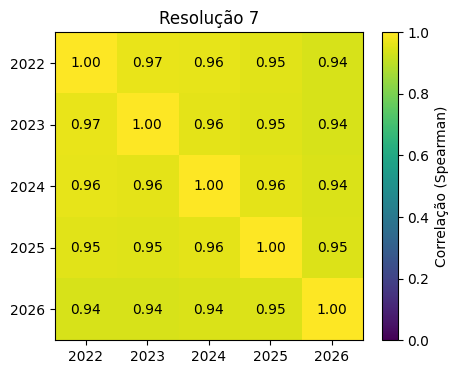

In [11]:
im = heatmap_corr(persistencia(df_raw, 7), "Resolução 7")
plt.colorbar(im, label="Correlação (Spearman)")
plt.show()

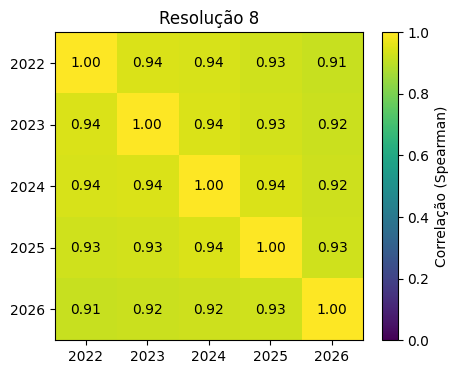

In [12]:
im = heatmap_corr(persistencia(df_raw, 8), "Resolução 8")
plt.colorbar(im, label="Correlação (Spearman)")
plt.show()

A resolução H3 7 foi escolhida por equilibrar detalhe espacial (regiões/bairros), densidade de dados, e porque, como a concentração dos crimes em poucas células e a esparsidade se mantêm em todas as resoluções (6 a 9) e o ranking espacial das células é muito estável entre os anos (Spearman de 0,94 a 0,97), mudar a resolução pouco altera a dificuldade do problema.

In [13]:
df_raw["H3"] = [h3.latlng_to_cell(la, lo, 7) for la, lo in zip(df_raw["LATITUDE"], df_raw["LONGITUDE"])]

In [14]:
df_raw.to_csv('../datasets/database_processed_h3.csv', index=False)